<a href="https://colab.research.google.com/github/ninkkka/data_analysis_labs/blob/main/lab3/lab3_dbscan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Лабораторная работа №3**
## **Кластерный анализ методом DBSCAN**

**Цель:** Провести сегментацию потребителей леденцоы методов DBSCAN на основе мотивов их потребления

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

from sklearn.metrics import silhouette_score

In [12]:
df = pd.read_csv('Леденцы.dat', sep=';')

feature_cols = [f'V{i}' for i in range(1, 12)]

X = df[feature_cols].values

## **Подбор eps**

Для DBSCAN нужно выбрать два параметра:
- **eps** - радиус, в котором ищем соседей
- **min_samples** - сколько точек должно быть в этом радиусе, включая саму точку, чтобы она считалась ядерной

Пока берем min_samples = 15 и строим график расстояний до 15-го ближайшего объекта. По резкому росту расстояний можно примерно определить подходящий eps

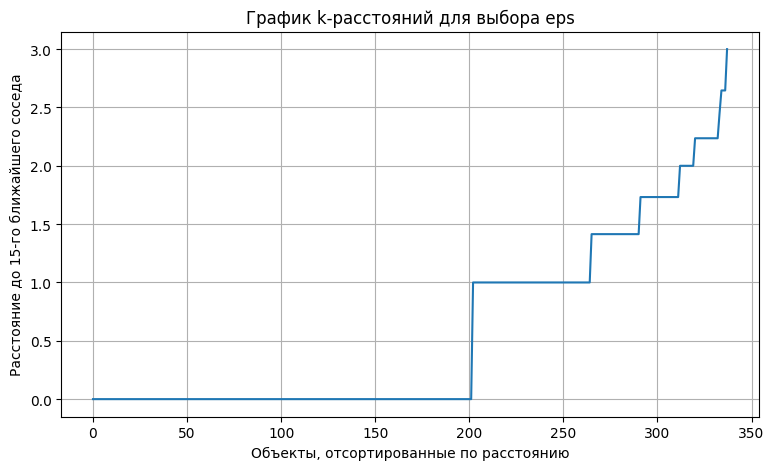

In [13]:
min_samples = 15

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X)

distances, indices = neighbors.kneighbors(X)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel('Объекты, отсортированные по расстоянию')
plt.ylabel('Расстояние до 15-го ближайшего соседа')
plt.title('График k-расстояний для выбора eps')
plt.grid()
plt.show()

## **Проверка разных eps**

На графике нет одного очевидного изгиба, поэтому проверим несколько значений eps

При маленьком радиусе больше объектов может оказаться шумом. При слишком большом радиусе разные кластеры могут объединиться

In [14]:
for eps in [1.2, 1.5, 1.8, 2.0, 2.3]:
    model = DBSCAN(
    eps=eps,
    min_samples=15
    )

    labels = model.fit_predict(X)

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    print(
        f'eps={eps}: '
        f'кластеров={n_clusters}, '
        f'шумовых объектов={n_noise}'
    )

eps=1.2: кластеров=6, шумовых объектов=69
eps=1.5: кластеров=6, шумовых объектов=44
eps=1.8: кластеров=4, шумовых объектов=10
eps=2.0: кластеров=3, шумовых объектов=4
eps=2.3: кластеров=3, шумовых объектов=4


## **Выбор параметров**

При eps = 1.2 получилось 6 кластеров и 69 шумовых объектов, при eps = 1.5 - 6 кластеров и 44 шумовых объекта

Выбираем eps = 1.8 и min_samples = 15: получаем 4 кластера и всего 10 шумовых объектов

При увеличении eps до 2.0 кластеров становится уже 3. Поэтому 1.8 выглядит подходящим компромиссом: шума немного, но отдельные группы еще сохраняются

In [15]:
dbscan = DBSCAN(eps=1.8, min_samples=15)

df['cluster_dbscan'] = dbscan.fit_predict(X)

print(df['cluster_dbscan'].value_counts().sort_index())

mask = df['cluster_dbscan'] != -1

score = silhouette_score(
    X[mask],
    df.loc[mask, 'cluster_dbscan']
)

print('Silhouette без шума:', round(score, 3))

cluster_dbscan
-1     10
 0    110
 1    100
 2     61
 3     57
Name: count, dtype: int64
Silhouette без шума: 0.745


## **Результаты кластеризации**

DBSCAN выделил 4 кластера: 110, 100, 61 и 57 покупателей. Ещё 10 человек (около 3%) попали в шум и получили метку -1

Silhouette без шумовых объектов = 0.745. Значение достаточно высокое, значит, выделенные группы хорошо разделены

Шум исключаем из расчета силуэта, поэтому эта оценка относится только к 328 покупателям, попавшим в кластеры

Далее считаем средние оценки по каждому признаку внутри кластеров. Так можно понять, какие мотивы покупки преобладают в каждой группе

Шумовые объекты пока не учитываем, так как они не образуют отдельный кластер

In [16]:
cluster_means = (
    df[df['cluster_dbscan'] != -1]
    .groupby('cluster_dbscan')[feature_cols]
    .mean()
)

cluster_means.round(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster_dbscan,,,,,,,,,,,
0,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
1,2.89,2.82,2.75,2.59,2.66,2.63,2.73,2.87,4.95,4.82,4.87
2,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
3,3.00,3.00,3.00,2.95,2.95,2.95,4.91,4.91,3.00,3.00,3.00


## **Интерпретация кластеров**

- Кластер 0 (110 человек) - свежесть и уверенность, высокие оценки V1–V4
- Кластер 1 (100 человек) - лечебные свойства, высокие оценки V9–V11
- Кластер 2 (61 человек) - сладкий вкус, высокие оценки V5–V6
- Кластер 3 (57 человек) - концентрация и отвлечение, высокие оценки V7–V8

Тепловая карта ниже помогает увидеть эти различия по цветам

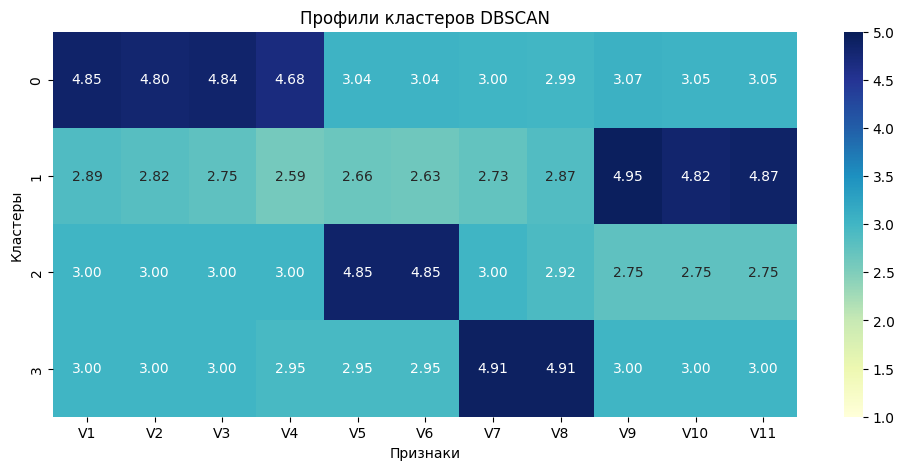

In [17]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    cluster_means,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=1,
    vmax=5
)

plt.title('Профили кластеров DBSCAN')
plt.xlabel('Признаки')
plt.ylabel('Кластеры')
plt.show()

## **Анализ шума**

DBSCAN отнес 10 покупателей к шуму. Это не обязательно ошибки в данных - просто вокруг этих объектов недостаточно плотная область

Посмотрим на их ответы, чтобы понять, чем они отличаются от основных групп

In [18]:
noise = df[df['cluster_dbscan'] == -1]

print('Количество шумовых объектов:', len(noise))

noise[feature_cols].T

Количество шумовых объектов: 10


,112,139,177,184,185,188,190,204,308,324
V1,2,2,2,2,2,2,2,2,3,3
V2,4,4,4,2,2,4,2,2,2,2
V3,4,4,4,2,2,4,2,2,2,2
V4,4,4,4,2,2,4,2,2,2,2
V5,2,2,2,2,2,2,2,2,2,2
V6,2,2,2,2,2,2,2,2,3,3
V7,2,2,2,4,4,2,4,4,5,5
V8,3,3,3,4,4,3,4,4,5,5
V9,5,5,5,5,5,5,5,5,3,3
V10,5,5,4,5,5,5,4,5,3,3


Сравним средние оценки шумовых покупателей со средними по всей выборке

У шумовых покупателей выше оценки лечебных свойств (V9–V11) и ниже оценки свежести и сладкого вкуса (V1–V6)

При этом у некоторых покупателей одновременно высокие оценки лечебных свойств и концентрации. Такие сочетания отличаются от типичных профилей основных кластеров

In [19]:
noise_means = noise[feature_cols].mean()

comparison = pd.DataFrame({
    'Шумовые покупатели': noise_means,
    'Все покупатели': df[feature_cols].mean()
})

comparison.round(2)

,Шумовые покупатели,Все покупатели
V1,2.2,3.54
V2,2.8,3.53
V3,2.8,3.52
V4,2.8,3.41
V5,2.0,3.21
V6,2.2,3.20
V7,3.4,3.25
V8,3.8,3.29
V9,4.6,3.60
V10,4.4,3.55


## **Визуализация кластеров**

У нас 11 признаков, поэтому для графика используем PCA - сокращаем количество измерений до двух

Цветами показываем четыре кластера, а чёрными крестиками - шум

**Важно**: DBSCAN работал со всеми 11 признаками. PCA нужен только для того, чтобы показать результат на плоскости

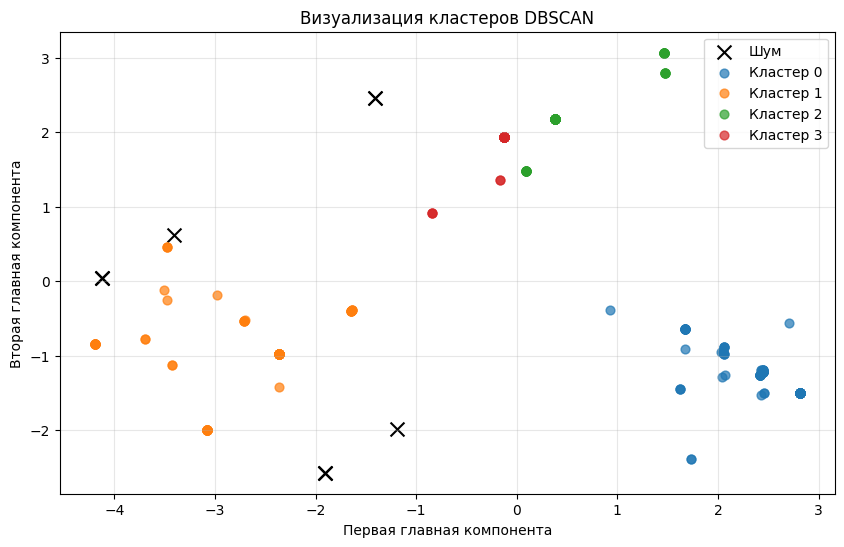

Объяснённая дисперсия: 0.78


In [20]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 6))

for cluster in sorted(df['cluster_dbscan'].unique()):
    mask = df['cluster_dbscan'] == cluster

    if cluster == -1:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            c='black',
            marker='x',
            s=100,
            label='Шум'
        )
    else:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            s=40,
            alpha=0.7,
            label=f'Кластер {cluster}'
        )

plt.title('Визуализация кластеров DBSCAN')
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(
'Объяснённая дисперсия:',
round(pca.explained_variance_ratio_.sum(), 3)
)

## **Итог**

С помощью DBSCAN удалось выделить 4 группы покупателей по мотивам потребления леденцов

Для кластеризации выбраны eps = 1.8 и min_samples = 15. При этих параметрах 328 покупателей распределены по кластерам, а 10 отнесены к шуму

Получились четыре сегмента: свежесть, лечебные свойства, сладкий вкус и концентрация

Silhouette без шума составил 0.745. Полученные группы достаточно хорошо разделены, а шумовые наблюдения позволяют отдельно изучить покупателей с нетипичными профилями

Главное отличие DBSCAN от предыдущих методов - количество кластеров не задается заранее, а определяется по плотности данных